# Cell 1: RT-DETR Minimalist Congestion Inference

In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 5.7 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Hunting for custom RT-DETR weights...
Success! Found custom RT-DETR weights at: /kaggle/input/datasets/sharminaktermukta/rtdetr-weight/best.pt

--- Processing Image 1/3 ---


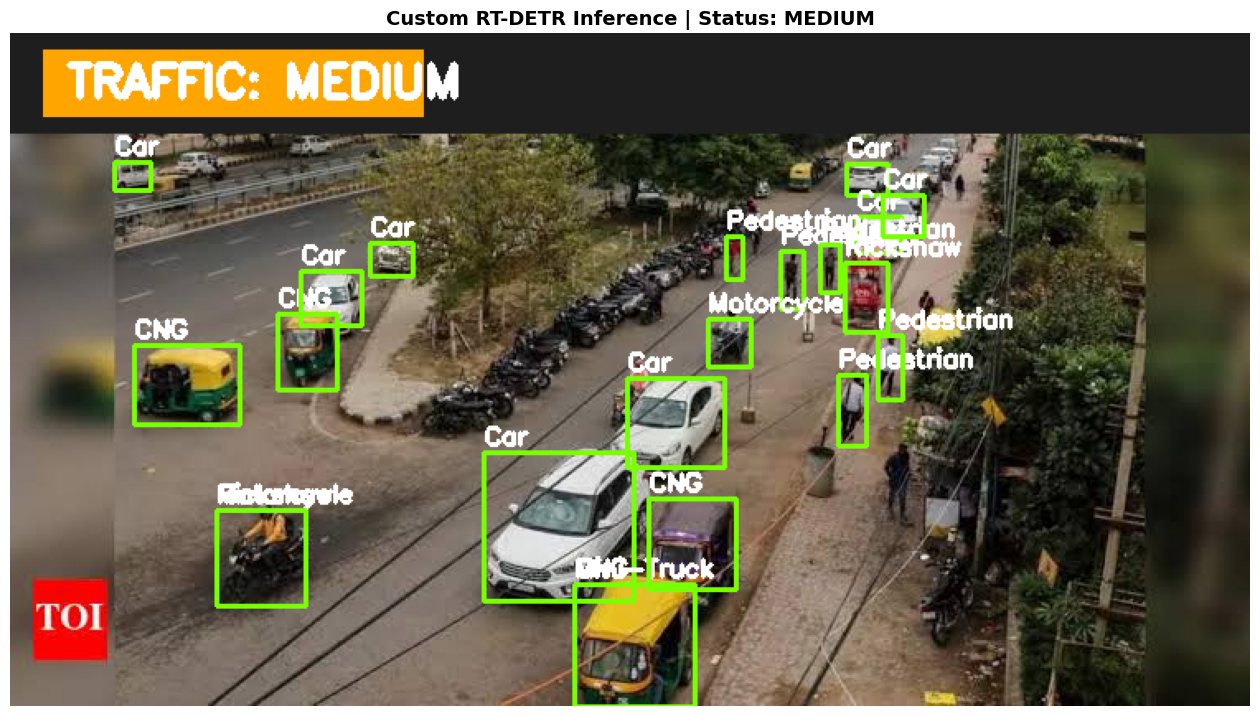


--- Processing Image 2/3 ---


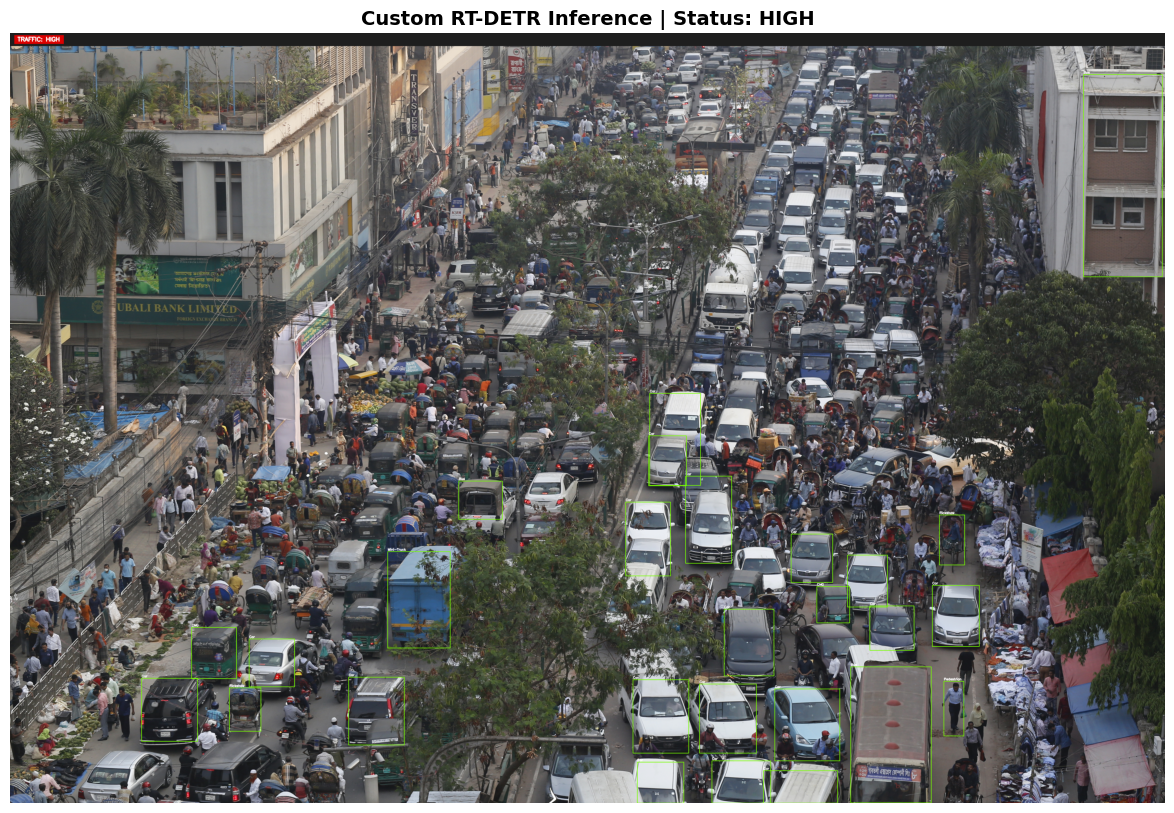


--- Processing Image 3/3 ---


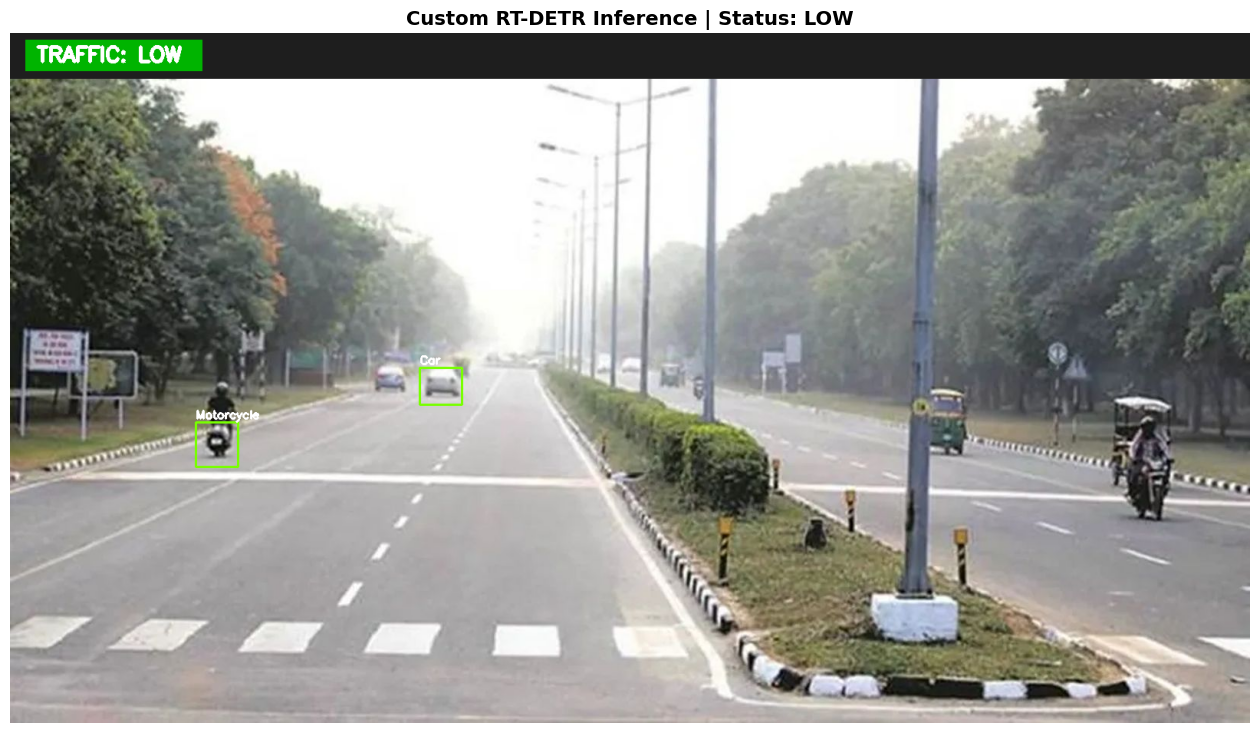

In [2]:
import os
import cv2
import requests
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import RTDETR

print("Hunting for custom RT-DETR weights...")

# 1. Auto-Detect Custom RT-DETR Weights
MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if 'best' in file and file.endswith('.pt'):
            MODEL_PATH = os.path.join(root, file)
            break
    if MODEL_PATH: break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find best.pt. Please upload your custom RT-DETR weights via 'Add Input'.")

print(f"Success! Found custom RT-DETR weights at: {MODEL_PATH}")
model = RTDETR(MODEL_PATH)

# PCU Weights mapping directly to your 9 trained classes
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}
low_cutoff, high_cutoff = 8.45, 15.80

def rtdetr_minimalist_analyzer(image_path):
    img = cv2.imread(image_path)
    h, w, _ = img.shape
    
    total_pcu = 0.0
    
    # Predict directly with your custom trained Transformer
    results = model.predict(source=image_path, conf=0.35, verbose=False)[0]
    
    for box in results.boxes:
        cls_id = int(box.cls[0].item())
        predicted_class = results.names[cls_id]
        conf = float(box.conf[0].item())
        
        total_pcu += PCU_WEIGHTS.get(predicted_class, 0.0)
        
        # Draw bounding boxes (Optional: you can comment these 3 lines out if you want ONLY the top banner)
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 120), 2)
        cv2.putText(img, f"{predicted_class}", (x1, max(15, y1 - 5)), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

    # Status Evaluation
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)      
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)    
    else:
        status, banner_color = "HIGH", (0, 0, 220)      

    # THE FIX: Ultra-Minimalist HUD Banner (No PCU counts, no object numbers)
    cv2.rectangle(img, (0, 0), (w, 60), (30, 30, 30), -1)
    cv2.rectangle(img, (20, 10), (250, 50), banner_color, -1)
    cv2.putText(img, f"TRAFFIC: {status}", (35, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 3)

    return img, status

# --- EXECUTION TEST ---
IMAGE_URLS = [
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSXkkWJHQ-Rd5cKZVvuTBbBH5HTM2zKKpVW6HwTaBN4CwYznVnj9dMGh4E&s=10",
    "https://static.time.com/v3/assets/bltea6093859af6183b/bltd4c970056f6da5af/698a40c922fb856f5de2f1ba/Dhaka-traffic.jpg?branch=production", 
    "https://cf-img-a-in.tosshub.com/sites/visualstory/wp/2024/05/Chandigarh.webp?size=*:900"
]

headers = {'User-Agent': 'Mozilla/5.0'}

for i, url in enumerate(IMAGE_URLS):
    download_path = f"/kaggle/working/rtdetr_test_RAW_{i+1}.jpg"
    output_path = f"/kaggle/working/rtdetr_test_ANALYZED_{i+1}.jpg" 

    print(f"\n--- Processing Image {i+1}/3 ---")
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        with open(download_path, 'wb') as f:
            f.write(response.content)
            
        rendered_frame, level = rtdetr_minimalist_analyzer(download_path)
        cv2.imwrite(output_path, rendered_frame)
        
        plt.figure(figsize=(16, 10))
        plt.imshow(cv2.cvtColor(rendered_frame, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.title(f"Custom RT-DETR Inference | Status: {level}", fontsize=14, fontweight='bold')
        plt.show()

# RT-DETR Test Set PCU Benchmark

Locating test images split...
Found 2368 unseen test images in: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Locating trained RT-DETR weights...
Loading RT-DETR weights from: /kaggle/input/datasets/sharminaktermukta/rtdetr-weight/best.pt

Running Calibrated RT-DETR PCU evaluation on test split...


100%|██████████| 2368/2368 [04:15<00:00,  9.28it/s]



Saved detailed results table to: /kaggle/working/rtdetr_test_pcu_results.csv

       RT-DETR TEST SPLIT CONGESTION SUMMARY       
                  Image Count  Percentage (%)  Mean PCU
congestion_level                                       
HIGH                     1863           78.67     27.32
LOW                       106            4.48      6.14
MEDIUM                    399           16.85     12.65

Overall Mean PCU on Test Set: 23.90


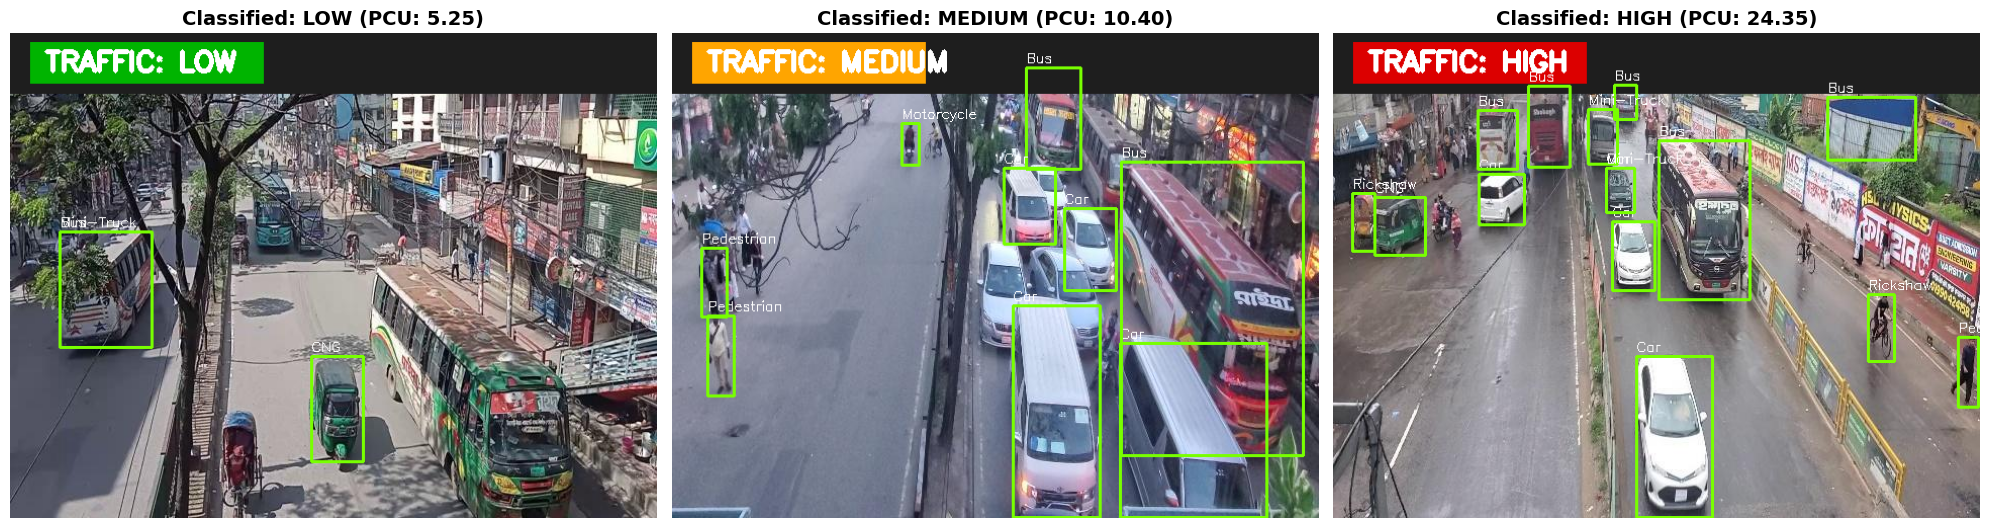

In [3]:
import os
import cv2
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics import RTDETR

# 1. PCU Standards & Thresholds
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}
LOW_CUTOFF, HIGH_CUTOFF = 8.45, 15.80

# 2. Locate Test Images Directory
print("Locating test images split...")
TEST_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if root.endswith(os.path.join('test', 'images')):
        TEST_DIR = root
        break

if not TEST_DIR:
    raise FileNotFoundError("Could not find 'test/images'. Ensure your prepared dataset is added via 'Add Input'.")

image_files = sorted(glob.glob(os.path.join(TEST_DIR, '*.[jJ][pP][gG]')) + 
                      glob.glob(os.path.join(TEST_DIR, '*.[pP][nN][gG]')))
print(f"Found {len(image_files)} unseen test images in: {TEST_DIR}")

# 3. Locate RT-DETR Model Weights
print("Locating trained RT-DETR weights...")
MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.endswith('.pt') and ('rtdetr' in root.lower() or 'rtdetr' in f.lower() or f == 'best.pt'):
            MODEL_PATH = os.path.join(root, f)
            break
    if MODEL_PATH:
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find RT-DETR 'best.pt' weights. Check 'Add Input'.")

print(f"Loading RT-DETR weights from: {MODEL_PATH}")
model = RTDETR(MODEL_PATH)

# 4. Batch Inference & PCU Aggregation Loop
results_data = []
sample_visuals = {'LOW': None, 'MEDIUM': None, 'HIGH': None}

print("\nRunning Calibrated RT-DETR PCU evaluation on test split...")

# THE FIX: Upgraded inference parameters
predictions = model.predict(
    source=TEST_DIR, 
    conf=0.20,           # Lowered to catch dark/nighttime cars (Fixes Image 1)
    imgsz=1024,          # Increased resolution to catch distant traffic jams (Fixes Image 2)
    iou=0.45,            # Stricter intersection-over-union 
    agnostic_nms=True,   # Prevents double-counting a Bus as both a Bus and a Truck (Fixes Image 3)
    stream=True, 
    verbose=False
)

for idx, result in enumerate(tqdm(predictions, total=len(image_files))):
    img_path = result.path
    img_name = os.path.basename(img_path)
    
    total_pcu = 0.0
    detected_counts = {cls: 0 for cls in PCU_WEIGHTS}
    valid_boxes = []
    
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        
        # Filter microscopic false positives that falsely inflate PCU
        if x2 - x1 < 15 or y2 - y1 < 15:
            continue
            
        cls_id = int(box.cls[0].item())
        cls_name = result.names[cls_id]
        
        if cls_name in PCU_WEIGHTS:
            total_pcu += PCU_WEIGHTS[cls_name]
            detected_counts[cls_name] += 1
            valid_boxes.append((x1, y1, x2, y2, cls_name))
            
    # Classify Congestion
    if total_pcu < LOW_CUTOFF:
        level = "LOW"
    elif total_pcu <= HIGH_CUTOFF:
        level = "MEDIUM"
    else:
        level = "HIGH"
        
    results_data.append({
        'image': img_name,
        'pcu_score': round(total_pcu, 2),
        'congestion_level': level,
        **detected_counts
    })
    
    # Store 1 sample of each category for visual display
    if sample_visuals[level] is None:
        raw_img = cv2.imread(img_path)
        h, w, _ = raw_img.shape
        
        # Overlay Minimalist HUD
        banner_color = (0, 180, 0) if level == "LOW" else ((0, 165, 255) if level == "MEDIUM" else (0, 0, 220))
        cv2.rectangle(raw_img, (0, 0), (w, 60), (30, 30, 30), -1)
        cv2.rectangle(raw_img, (20, 10), (250, 50), banner_color, -1)
        cv2.putText(raw_img, f"TRAFFIC: {level}", (35, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 3)
        
        # Draw bounding boxes (only the valid, filtered ones)
        for (x1, y1, x2, y2, cls_name) in valid_boxes:
            cv2.rectangle(raw_img, (x1, y1), (x2, y2), (0, 255, 120), 2)
            cv2.putText(raw_img, cls_name, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
            
        sample_visuals[level] = (raw_img, total_pcu)

# 5. Export Results to CSV
df_results = pd.DataFrame(results_data)
csv_output_path = '/kaggle/working/rtdetr_test_pcu_results.csv'
df_results.to_csv(csv_output_path, index=False)
print(f"\nSaved detailed results table to: {csv_output_path}")

# 6. Statistical Summary
print("\n" + "="*50)
print("       RT-DETR TEST SPLIT CONGESTION SUMMARY       ")
print("="*50)
summary = df_results['congestion_level'].value_counts()
pcts = df_results['congestion_level'].value_counts(normalize=True) * 100

summary_table = pd.DataFrame({
    'Image Count': summary,
    'Percentage (%)': pcts.round(2),
    'Mean PCU': df_results.groupby('congestion_level')['pcu_score'].mean().round(2)
})
print(summary_table.to_string())
print(f"\nOverall Mean PCU on Test Set: {df_results['pcu_score'].mean():.2f}")
print("="*50)

# 7. Display Visual Samples
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for i, level in enumerate(['LOW', 'MEDIUM', 'HIGH']):
    if sample_visuals[level] is not None:
        img, score = sample_visuals[level]
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Classified: {level} (PCU: {score:.2f})", fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, f"No {level} instances found", ha='center', va='center')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# 